# 01 — Premier regard sur les données brutes

Avant d'écrire la moindre règle de nettoyage, on a voulu regarder les fichiers tels qu'ils arrivent. On s'est posé quatre questions :

1. à quoi ressemble un fichier de capteur Sensor.Community ?
2. quelles pannes y trouve-t-on, et combien ?
3. les heures du capteur et de la station EEA désignent-elles bien la même heure ?
4. faut-il utiliser la sonde d'humidité branchée sur certains capteurs ?

**Quelques mots de vocabulaire.**
- Le **PM2.5** est la masse des particules de moins de 2,5 µm par mètre cube d'air (en µg/m³).
- Le **SDS011** est le capteur optique à 20 € le plus répandu chez Sensor.Community.
- Une **station de référence** est une station officielle de l'EEA (Agence européenne pour l'environnement), avec un instrument certifié.
- Une **paire** est un capteur SDS011 avec la station la plus proche, à 1,5 km au plus.

**Périmètre :** l'Allemagne, en 2024 et 2025.

Les données viennent de `scripts/01_telecharger.py` (voir le README).

On charge la liste des paires construite par le script 01.

In [1]:
import matplotlib.pyplot as plt
import polars as pl

from aircalib import nettoyage as N
from aircalib import parametres as P

BRUT = P.dossier_donnees() / "brut"
FIGURES = P.RAPPORTS / "figures"
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_tbl_rows(12)
pl.Config.set_tbl_width_chars(140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
paires = pl.read_parquet(BRUT / "paires.parquet")
stations = paires["station"].n_unique()
print(f"{paires.height} capteurs SDS011 à 1,5 km ou moins d'une station, {stations} stations")

569 capteurs SDS011 à 1,5 km ou moins d'une station, 180 stations


On a 569 capteurs pour 180 stations, soit trois capteurs par station en moyenne. Plusieurs capteurs partagent donc la même station : il faudra s'en souvenir au moment de découper les données pour la validation (notebook 03).

## 1. Un fichier de capteur

Les mesures sont rangées par capteur et par mois. On ouvre le dernier mois du capteur le plus proche de sa station.

In [2]:
capteur = paires.sort("distance_km")["capteur"][0]
fichier = sorted((BRUT / "capteurs" / str(capteur)).glob("*.parquet"))[-1]
mois = pl.read_parquet(fichier)
print(f"capteur {capteur}, fichier {fichier.parent.name}/{fichier.name} : {mois.height} mesures")
mois.head(5)

capteur 81044, fichier 81044/2025-12.parquet : 14430 mesures


horodatage,pm10,pm25,lat,lon
datetime[μs],f64,f64,f64,f64
2025-12-01 00:01:43,22.0,19.6,51.756293,14.327936
2025-12-01 00:04:09,21.33,19.03,51.756293,14.327936
2025-12-01 00:06:35,22.67,20.2,51.756293,14.327936
2025-12-01 00:09:01,20.27,18.17,51.756293,14.327936
2025-12-01 00:11:27,21.63,19.3,51.756293,14.327936


Chaque ligne donne une mesure : l'heure (UTC), le PM10, le PM2.5 et la position déclarée par le propriétaire. Ici, une mesure arrive toutes les 146 secondes environ (≈ 2,5 min).

À ce rythme, décembre devrait contenir environ 18 300 mesures ; on n'en a que 14 430, soit environ 79 %. Le capteur a donc eu des trous (coupure de wifi ou de courant), ce qui est banal chez un particulier.

**Ce que ça veut dire :** il faudra moyenner les mesures par heure pour les comparer à la station, qui donne une valeur par heure. Il faudra aussi décider à partir de combien de mesures une heure est « assez remplie ».

## 2. Les pannes

On compte, sur toutes les mesures brutes des 569 capteurs, les valeurs qu'on sait impossibles ou suspectes :
- `vides` : PM2.5 ou PM10 absent ;
- `negatives` : valeur négative (code d'erreur) ;
- `plafond` : 999,9 µg/m³, la valeur maximale que le SDS011 sait écrire ;
- `zero_zero` : PM2.5 = PM10 = 0 ;
- `pm25_sup_pm10` : PM2.5 > PM10, ce qui est physiquement impossible puisque les PM2.5 font partie des PM10.

(Polars lit les fichiers en flux : le comptage sur environ 150 millions de lignes prend quelques secondes.)

In [3]:
lecture = pl.scan_parquet(BRUT / "capteurs" / "*" / "*.parquet", include_file_paths="fichier").with_columns(
    capteur=pl.col("fichier").str.extract(r"capteurs/(\d+)/").cast(pl.Int64)
)
apparies = lecture.filter(pl.col("capteur").is_in(paires["capteur"].implode()))
pannes = apparies.select(
    mesures=pl.len(),
    vides=(pl.col("pm25").is_null() | pl.col("pm10").is_null()).sum(),
    negatives=(pl.col("pm25") < 0).sum(),
    plafond=(pl.col("pm25") >= P.PM25_PLAFOND).sum(),
    zero_zero=((pl.col("pm25") == 0) & (pl.col("pm10") == 0)).sum(),
    pm25_sup_pm10=(pl.col("pm25") > pl.col("pm10")).sum(),
).collect()
pannes

mesures,vides,negatives,plafond,zero_zero,pm25_sup_pm10
u32,u32,u32,u32,u32,u32
148636757,384694,0,830792,1981101,119


Sur 148,6 millions de mesures :
- **0,26 %** sont vides ;
- **0,56 %** sont bloquées au plafond ;
- **1,3 %** valent 0/0 ;
- seulement 119 ont un PM2.5 supérieur au PM10 ;
- et aucune n'est négative.

**Ce que ça veut dire :** globalement, les fichiers sont plutôt propres. Mais une seule mesure à 999,9 suffit à fausser une moyenne horaire : avec 25 mesures par heure, elle ajoute à elle seule une quarantaine de µg/m³.

Le cas du 0/0 est moins simple. Un 0/0 isolé peut être de l'air très propre, mais un capteur qui renvoie 0/0 pendant des heures est en panne. On regarde à quoi ressemblent les capteurs les plus touchés.

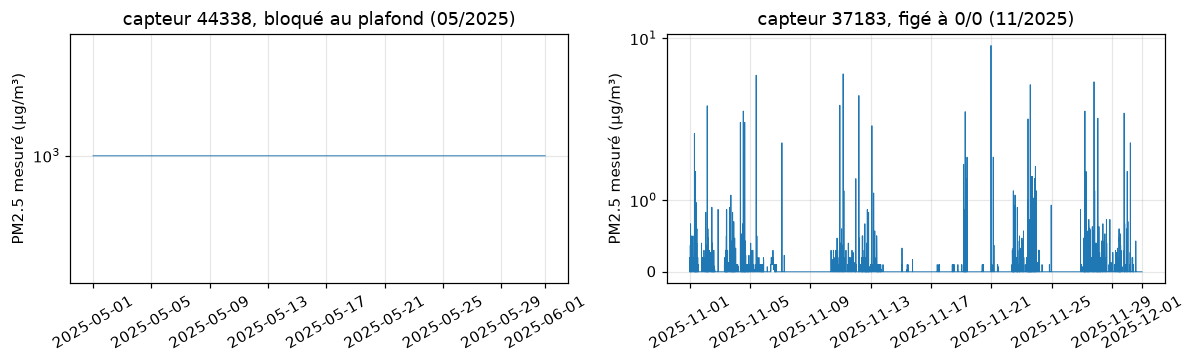

In [4]:
par_capteur = (
    apparies.group_by("capteur")
    .agg(
        plafond=(pl.col("pm25") >= P.PM25_PLAFOND).sum(),
        zero=((pl.col("pm25") == 0) & (pl.col("pm10") == 0)).sum(),
    )
    .collect()
)
sature = par_capteur.sort("plafond", descending=True)["capteur"][0]
fige = par_capteur.sort("zero", descending=True)["capteur"][0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, (titre, c, colonne) in zip(
    axes, (("bloqué au plafond", sature, "plafond"), ("figé à 0/0", fige, "zero")), strict=True
):
    serie = pl.read_parquet(BRUT / "capteurs" / str(c) / "*.parquet").sort("horodatage")
    mois_panne = (
        serie.filter(
            (pl.col("pm25") >= P.PM25_PLAFOND)
            if colonne == "plafond"
            else (pl.col("pm25") == 0) & (pl.col("pm10") == 0)
        )["horodatage"]
        .dt.truncate("1mo")
        .mode()[0]
    )
    morceau = serie.filter(pl.col("horodatage").dt.truncate("1mo") == mois_panne)
    ax.plot(morceau["horodatage"], morceau["pm25"], lw=0.6)
    ax.set_yscale("symlog")
    ax.set_title(f"capteur {c}, {titre} ({mois_panne:%m/%Y})")
    ax.set_ylabel("PM2.5 mesuré (µg/m³)")
    ax.tick_params(axis="x", labelrotation=30)
fig.tight_layout()
fig.savefig(FIGURES / "01_exemples_de_pannes.png")

À gauche, le capteur renvoie 999,9 pendant tout le mois de mai 2025 : ce n'est évidemment pas de la pollution, le capteur est cassé. À droite, le capteur reste collé à 0 pendant des jours entiers, avec quelques courtes périodes où il mesure à nouveau (échelle logarithmique).

**Décision pour le nettoyage (notebook 02) :**
- on retire les mesures vides, négatives, au plafond ou avec PM2.5 > PM10 ;
- on ne retire le 0/0 que lorsqu'il dure au moins une heure d'affilée, pour ne pas jeter des mesures d'air propre.

On ne met **aucun filtre statistique** (du type « on retire ce qui dépasse 3 écarts-types ») : un vrai pic de pollution ressemble à une valeur aberrante, et c'est justement ce qu'on veut apprendre à corriger.

## 3. L'horloge de la station

Les fichiers EEA donnent pour chaque heure un début (`Start`) et une fin (`End`). Il faut savoir si `Start = 14:00` correspond à l'heure 14 h–15 h UTC (ce qu'on attendrait) ou à une autre. Si on se trompe d'une heure, on compare le capteur à la mauvaise heure de la station, et le modèle apprend sur des couples faux.

**Méthode.** Les niveaux de pollution changent lentement, donc décaler d'une heure ne change presque rien à leur corrélation. Les *variations* d'une heure à l'autre, elles, sont beaucoup plus nettes. On note $\Delta c_t = c_t - c_{t-1}$ la variation du capteur et $\Delta s_t$ celle de la station. Pour chaque décalage $k$ (en heures), on calcule

$$\rho(k) = \mathrm{corr}\left(\Delta c_t,\ \Delta s_{t+k}\right)$$

Le bon $k$ est celui qui maximise $\rho$. On le fait sur les 40 paires les plus proches (moins de 300 m), où capteur et station voient vraiment le même air. Ici, on prend la référence EEA *telle quelle*, sans correction.

37 paires à moins de 0.27 km
meilleur décalage : {-3: 1, 1: 35, 2: 1}


decalage_h,correlation
i64,f64
-3,-0.017
-2,-0.01
-1,0.0
0,0.102
1,0.426
2,0.168
3,0.014


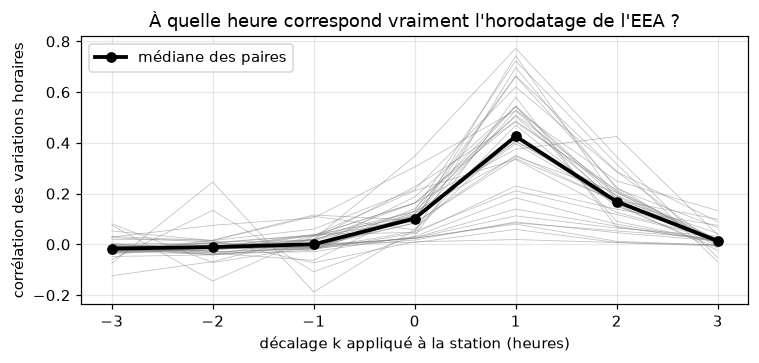

In [5]:
proches = paires.sort("distance_km").head(40)
eea = pl.read_parquet(BRUT / "eea" / "*.parquet")
reference_brute = eea.filter(
    pl.col("validite").is_in(P.EEA_VALIDITES), pl.col("valeur") != P.EEA_MANQUANT
).select("point", heure="debut", reference="valeur")
courbes = []
for c, point in proches.select("capteur", "point").iter_rows():
    serie = pl.read_parquet(BRUT / "capteurs" / str(c) / "*.parquet")
    serie = list(N.retirer_valeurs_impossibles(serie).values())[-1]
    horaire = N.moyennes_horaires(serie, N.cadence_s(serie))
    paire = horaire.join(reference_brute.filter(pl.col("point") == point), on="heure")
    if paire.height > P.HEURES_MIN_CONTROLE:
        courbes.append(N.correlations_decalees(paire).with_columns(capteur=pl.lit(c)))
courbes = pl.concat(courbes)
meilleur = courbes.sort("correlation", descending=True).group_by("capteur").first()
print(f"{meilleur.height} paires à moins de {proches['distance_km'].max():.2f} km")
print("meilleur décalage :", dict(meilleur["decalage_h"].value_counts().sort("decalage_h").iter_rows()))
mediane = courbes.group_by("decalage_h").agg(pl.col("correlation").median()).sort("decalage_h")
fig, ax = plt.subplots(figsize=(7, 3.4))
for _, part in courbes.group_by("capteur"):
    ax.plot(part["decalage_h"], part["correlation"], color="grey", lw=0.5, alpha=0.5)
ax.plot(
    mediane["decalage_h"], mediane["correlation"], color="k", lw=2.5, marker="o", label="médiane des paires"
)
ax.set_xlabel("décalage k appliqué à la station (heures)")
ax.set_ylabel("corrélation des variations horaires")
ax.set_title("À quelle heure correspond vraiment l'horodatage de l'EEA ?")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "01_horloge_eea.png")
mediane.with_columns(pl.col("correlation").round(3))

Sur les 37 paires qui ont assez d'heures communes, **35 donnent le meilleur accord pour $k = 1$**. La corrélation médiane passe de 0,10 sans décalage à 0,43 avec $k = 1$, puis retombe à 0,17 pour $k = 2$.

**Ce que ça veut dire :** la valeur que l'EEA étiquette `Start = 14:00` correspond en réalité à l'heure 13 h–14 h UTC du capteur. On ne sait pas exactement pourquoi (peut-être l'heure d'hiver d'Europe centrale, UTC+1), mais le résultat est très net et le même pour presque toutes les paires.

**Décision :** on corrige l'horodatage de la station avec $\text{heure UTC} = \text{Start} - 1\ \text{h}$ (paramètre `EEA_DECALAGE_H`). Sans ce contrôle, on aurait fait toute l'étude avec une heure de décalage sans s'en rendre compte.

## 4. Les sondes d'humidité des capteurs

On sait que le SDS011 réagit à l'humidité : par air très humide, les particules gonflent en absorbant de l'eau et le capteur compte plus de masse qu'il n'y en a. L'humidité sera donc une variable importante.

Beaucoup de capteurs Sensor.Community ont une petite sonde DHT22 ou BME280 branchée à côté. Cela donnerait l'humidité exactement au bon endroit, mais est-elle fiable ? On a téléchargé un échantillon de 100 sondes de chaque type pour janvier 2025, et on regarde quelle part de leurs mesures est bloquée à ≥ 99,9 % d'humidité. On compare à la même proportion dans les stations météo officielles du DWD (le service météo allemand) sur le même mois.

In [6]:
sondes = pl.read_parquet(BRUT / "sondes" / "*.parquet")
meteo = pl.read_parquet(BRUT / "dwd" / "*.parquet").filter(
    pl.col("heure").dt.month() == 1, pl.col("heure").dt.year() == 2025
)
saturation = (
    sondes.drop_nulls("humidite")
    .group_by("type")
    .agg(
        sondes=pl.col("capteur").n_unique(),
        mesures=pl.len(),
        saturees=(pl.col("humidite") >= P.SATURATION_PCT).mean(),
    )
    .sort("type")
)
officiel = meteo.drop_nulls("humidite").select(
    type=pl.lit("station officielle (DWD)"),
    sondes=pl.col("id_dwd").n_unique(),
    mesures=pl.len(),
    saturees=(pl.col("humidite") >= P.SATURATION_PCT).mean(),
)
pl.concat([saturation, officiel.cast(saturation.schema)]).with_columns(
    (100 * pl.col("saturees")).round(1).alias("% saturées")
).drop("saturees")

type,sondes,mesures,% saturées
str,u32,u32,f64
"""bme280""",71,1166835,50.6
"""dht22""",91,1525600,68.3
"""station officielle (DWD)""",107,79366,3.3


Sur janvier 2025 :
- **68 %** des mesures des DHT22 et **51 %** de celles des BME280 sont bloquées à 99,9–100 % d'humidité ;
- c'est seulement **3,3 %** pour les stations météo officielles.

**Ce que ça veut dire :** en hiver, ces petites sondes saturent la plupart du temps (condensation dans le boîtier, vieillissement). Une variable bloquée à 100 % ne dit plus rien au modèle, justement par air humide, quand on en a le plus besoin.

**Décision :** on prend l'humidité et la température de la **station DWD la plus proche** (6 km en médiane, 24 km au plus). C'est moins local, mais fiable, et disponible pour tous les capteurs, y compris ceux qui n'ont pas de sonde.

## Ce qu'on retient

- **Pannes :** les données brutes sont assez propres, mais il y a de vraies pannes, concentrées sur quelques capteurs (plafond à 999,9, plateaux 0/0). Des règles physiques simples suffisent pour les retirer.
- **Cadence :** un capteur envoie une mesure toutes les 2 à 5 minutes, avec des trous. On travaillera en moyennes horaires, en vérifiant qu'une heure est assez remplie.
- **Horloge :** l'horloge de l'EEA est décalée d'une heure. On la corrige ($\text{Start} - 1$ h).
- **Humidité :** elle viendra de la station DWD la plus proche, pas de la sonde du capteur.

Le notebook 02 applique ces règles et construit les paires capteur–station heure par heure.